# Recurrence graph construction from AR(p) prediction errors

This notebook simulates an AR(p) process with either uniform $U[-1,1]$ or normal $N(0,1)$ innovations, constructs forward sliding-window embeddings

$$Y_t^k = (X_t, X_{t+1}, \ldots, X_{t+k-1}),$$

learns a linear predictor for $X_{t+k}$ from $Y_t^k$ on a train set, and builds test-set graphs with edges

$$E_k^\tau = \{(t,s): e_t^k + e_s^k < \tau\}, \qquad e_t^k = |\hat X_{t+k} - X_{t+k}|.$$

The threshold `TAU` is chosen globally and is not fitted from the data.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401, needed for 3D projection

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)

## Global configuration

Change `INNOVATION_KIND` to `"uniform"` or `"normal"`. Change `TAU` directly when you want a stricter or looser graph threshold. It is intentionally not estimated from the prediction errors.

In [ ]:
SEED = 7
N = 1500
BURN_IN = 300

# Stable AR(3) example. You can replace this by any coefficient vector of length p.
PHI = np.array([0.65, -0.28, 0.12])
P = len(PHI)

INNOVATION_KIND = "normal"  # either "normal" or "uniform"
TRAIN_FRACTION = 0.70
K_VALUES = [2, 3, 5, 8, 12]

# Global graph threshold. This is chosen by the user, not from the data.
TAU = 0.75

## AR(p) simulation

In [ ]:
def sample_innovations(kind, size, rng):
    """Draw innovations from U[-1, 1] or N(0, 1)."""
    if kind == "uniform":
        return rng.uniform(-1.0, 1.0, size=size)
    if kind == "normal":
        return rng.normal(0.0, 1.0, size=size)
    raise ValueError("kind must be 'uniform' or 'normal'")


def generate_ar_process(phi, n, innovation_kind="normal", burn_in=300, seed=0):
    """Generate X_t = phi_1 X_{t-1} + ... + phi_p X_{t-p} + eps_t."""
    phi = np.asarray(phi, dtype=float)
    p = len(phi)
    rng = np.random.default_rng(seed)
    eps = sample_innovations(innovation_kind, n + burn_in, rng)
    x = np.zeros(n + burn_in)

    for t in range(p, n + burn_in):
        past = x[t - np.arange(1, p + 1)]
        x[t] = np.dot(phi, past) + eps[t]

    return x[burn_in:]


X = generate_ar_process(PHI, N, INNOVATION_KIND, burn_in=BURN_IN, seed=SEED)
time = np.arange(len(X))

print(f"Generated AR({P}) process with {INNOVATION_KIND} innovations")
print(f"phi = {PHI}")
print(f"mean={X.mean():.4f}, std={X.std():.4f}, min={X.min():.4f}, max={X.max():.4f}")

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(time, X, lw=1.0, color="black")
ax.set_title(f"AR({P}) process with {INNOVATION_KIND} innovations")
ax.set_xlabel("time index t")
ax.set_ylabel(r"$X_t$")
plt.show()

## Forward sliding-window embedding

For a fixed window length `k`, the forward embedding is

$$Y_t^k = (X_t, X_{t+1}, \ldots, X_{t+k-1}),$$

and the corresponding prediction target is $X_{t+k}$.

In [ ]:
def forward_sliding_window_embedding(x, k):
    """Return time indices t, windows Y_t^k, and targets X_{t+k}."""
    x = np.asarray(x, dtype=float)
    if k < 1:
        raise ValueError("k must be at least 1")
    if len(x) <= k:
        raise ValueError("time series must have length larger than k")

    t = np.arange(len(x) - k)
    Y = np.column_stack([x[j:j + len(x) - k] for j in range(k)])
    target = x[k:]
    return t, Y, target


def plot_forward_embedding_clouds(x, stride=1):
    """Show the 2D and 3D forward sliding-window point clouds next to each other."""
    _, Y2, _ = forward_sliding_window_embedding(x, 2)
    _, Y3, _ = forward_sliding_window_embedding(x, 3)

    Y2_plot = Y2[::stride]
    Y3_plot = Y3[::stride]

    fig = plt.figure(figsize=(13, 5))
    ax2 = fig.add_subplot(1, 2, 1)
    ax3 = fig.add_subplot(1, 2, 2, projection="3d")

    ax2.scatter(Y2_plot[:, 0], Y2_plot[:, 1], s=8, alpha=0.45, color="#2f6f9f")
    ax2.set_title(r"2D cloud: $Y_t^2=(X_t, X_{t+1})$")
    ax2.set_xlabel(r"$X_t$")
    ax2.set_ylabel(r"$X_{t+1}$")
    ax2.set_aspect("equal", adjustable="box")

    ax3.scatter(Y3_plot[:, 0], Y3_plot[:, 1], Y3_plot[:, 2], s=8, alpha=0.35, color="#9f4f2f")
    ax3.set_title(r"3D cloud: $Y_t^3=(X_t, X_{t+1}, X_{t+2})$")
    ax3.set_xlabel(r"$X_t$")
    ax3.set_ylabel(r"$X_{t+1}$")
    ax3.set_zlabel(r"$X_{t+2}$")

    plt.tight_layout()
    plt.show()


plot_forward_embedding_clouds(X, stride=1)

## Train/test split and linear prediction

For every `k`, the train/test split is done over valid time indices $t = 0, \ldots, n-k-1$. The model is an ordinary least-squares linear regression with an intercept:

$$\widehat{X}_{t+k} = \beta_0 + \beta^\top Y_t^k.$$


In [ ]:
def chronological_train_test_split(t, Y, target, train_fraction=0.7):
    """Split valid windows chronologically, preserving time order."""
    n_obs = len(t)
    n_train = int(np.floor(train_fraction * n_obs))
    if n_train <= 0 or n_train >= n_obs:
        raise ValueError("train_fraction must leave at least one train and one test observation")

    return {
        "t_train": t[:n_train],
        "Y_train": Y[:n_train],
        "target_train": target[:n_train],
        "t_test": t[n_train:],
        "Y_test": Y[n_train:],
        "target_test": target[n_train:],
    }


def fit_linear_regression(Y, target):
    """Fit target = beta_0 + beta_1 Y_1 + ... + beta_k Y_k by least squares."""
    design = np.column_stack([np.ones(len(Y)), Y])
    beta, residuals, rank, singular_values = np.linalg.lstsq(design, target, rcond=None)
    return beta


def predict_linear_regression(Y, beta):
    design = np.column_stack([np.ones(len(Y)), Y])
    return design @ beta


def fit_predict_for_k(x, k, train_fraction=0.7):
    t, Y, target = forward_sliding_window_embedding(x, k)
    split = chronological_train_test_split(t, Y, target, train_fraction=train_fraction)

    beta = fit_linear_regression(split["Y_train"], split["target_train"])
    pred_train = predict_linear_regression(split["Y_train"], beta)
    pred_test = predict_linear_regression(split["Y_test"], beta)

    split.update({
        "k": k,
        "beta": beta,
        "pred_train": pred_train,
        "pred_test": pred_test,
        "error_train": np.abs(pred_train - split["target_train"]),
        "error_test": np.abs(pred_test - split["target_test"]),
    })
    return split


prediction_results = {k: fit_predict_for_k(X, k, TRAIN_FRACTION) for k in K_VALUES}

for k, result in prediction_results.items():
    train_mae = result["error_train"].mean()
    test_mae = result["error_test"].mean()
    print(f"k={k:2d}: train MAE={train_mae:.4f}, test MAE={test_mae:.4f}, beta={result['beta']}")

In [ ]:
def plot_prediction_errors(prediction_results):
    fig, axes = plt.subplots(len(prediction_results), 1, figsize=(13, 2.7 * len(prediction_results)), sharex=False)
    if len(prediction_results) == 1:
        axes = [axes]

    for ax, (k, result) in zip(axes, prediction_results.items()):
        t_test = result["t_test"]
        target_test = result["target_test"]
        pred_test = result["pred_test"]
        error_test = result["error_test"]

        ax.plot(t_test + k, target_test, color="black", lw=1.0, label=r"$X_{t+k}$")
        ax.plot(t_test + k, pred_test, color="#2f6f9f", lw=1.0, alpha=0.85, label=r"$\hat X_{t+k}$")
        ax.fill_between(t_test + k, target_test, pred_test, color="#c44e52", alpha=0.18)
        ax.set_title(f"Test prediction for k={k}: MAE={error_test.mean():.4f}")
        ax.set_ylabel("value")
        ax.legend(loc="upper right", ncols=2)

    axes[-1].set_xlabel("time index t+k")
    plt.tight_layout()
    plt.show()


plot_prediction_errors(prediction_results)

## Graph construction on the test set

For each `k`, the vertex set is the test time index set `V_test = t_test`. An edge $(t, s)$ is added when

$$e_t^k + e_s^k < \tau.$$

The threshold `TAU` is global and manually chosen above.


In [ ]:
def build_error_threshold_graph(t_test, error_test, tau):
    """Build V_test and E_k^tau with edges where e_t + e_s < tau."""
    t_test = np.asarray(t_test, dtype=int)
    error_test = np.asarray(error_test, dtype=float)
    m = len(t_test)

    row, col = np.triu_indices(m, k=1)
    keep = error_test[row] + error_test[col] < tau
    edges = np.column_stack([t_test[row[keep]], t_test[col[keep]]])

    return {
        "vertices": t_test,
        "edges": edges,
        "errors": error_test,
        "tau": tau,
        "n_vertices": m,
        "n_edges": len(edges),
        "density": len(edges) / (m * (m - 1) / 2) if m > 1 else 0.0,
    }


graph_results = {}
for k, result in prediction_results.items():
    graph_results[k] = build_error_threshold_graph(result["t_test"], result["error_test"], TAU)

for k, graph in graph_results.items():
    print(
        f"k={k:2d}: |V_test|={graph['n_vertices']:4d}, "
        f"|E_k^tau|={graph['n_edges']:6d}, density={graph['density']:.4f}, tau={graph['tau']}"
    )

In [ ]:
def plot_error_threshold_graphs(x, prediction_results, graph_results, max_edges_to_draw=5000, seed=0):
    """Visualize E_k^tau for increasing k using process value as vertical position."""
    rng = np.random.default_rng(seed)
    n_graphs = len(graph_results)
    fig, axes = plt.subplots(n_graphs, 1, figsize=(14, 3.2 * n_graphs), sharex=True)
    if n_graphs == 1:
        axes = [axes]

    for ax, (k, graph) in zip(axes, graph_results.items()):
        vertices = graph["vertices"]
        errors = graph["errors"]
        edges = graph["edges"]

        x_pos = vertices + k
        y_pos = x[x_pos]
        pos = {int(t): (float(t + k), float(x[t + k])) for t in vertices}

        edges_to_draw = edges
        if len(edges_to_draw) > max_edges_to_draw:
            chosen = rng.choice(len(edges_to_draw), size=max_edges_to_draw, replace=False)
            edges_to_draw = edges_to_draw[chosen]

        for t, s in edges_to_draw:
            xt, yt = pos[int(t)]
            xs, ys = pos[int(s)]
            ax.plot([xt, xs], [yt, ys], color="#7a7a7a", alpha=0.035, lw=0.7, zorder=1)

        scatter = ax.scatter(
            x_pos,
            y_pos,
            c=errors,
            cmap="viridis_r",
            s=22,
            edgecolor="black",
            linewidth=0.2,
            zorder=2,
        )
        ax.set_ylabel(r"$X_{t+k}$")
        ax.set_title(
            f"k={k}, tau={graph['tau']} | "
            f"|V_test|={graph['n_vertices']}, |E|={graph['n_edges']}, density={graph['density']:.3f}"
        )
        fig.colorbar(scatter, ax=ax, label=r"$e_t^k$")

        if len(edges) > max_edges_to_draw:
            ax.text(
                0.01,
                0.93,
                f"showing {max_edges_to_draw:,} sampled edges of {len(edges):,}",
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75},
            )

    axes[-1].set_xlabel("test time index t+k")
    plt.tight_layout()
    plt.show()


plot_error_threshold_graphs(X, prediction_results, graph_results, max_edges_to_draw=5000, seed=SEED)

## Optional: adjacency matrices

These matrices make the edge rule visually explicit. A colored pixel means the corresponding pair of test vertices satisfies $e_t^k + e_s^k < \tau$.


In [ ]:
def plot_adjacency_matrices(graph_results):
    n_graphs = len(graph_results)
    fig, axes = plt.subplots(1, n_graphs, figsize=(3.2 * n_graphs, 3.2), constrained_layout=True)
    if n_graphs == 1:
        axes = [axes]

    for ax, (k, graph) in zip(axes, graph_results.items()):
        errors = graph["errors"]
        adjacency = (errors[:, None] + errors[None, :]) < graph["tau"]
        np.fill_diagonal(adjacency, False)
        ax.imshow(adjacency, cmap="Greys", interpolation="nearest", origin="lower")
        ax.set_title(f"k={k}\ndensity={graph['density']:.3f}")
        ax.set_xticks([])
        ax.set_yticks([])

    plt.show()


plot_adjacency_matrices(graph_results)

## Custom AR(p) experiment with uniform innovations

Use this section when you want to choose the AR order `p`, the global graph threshold `tau`, and the largest window length `k_max` yourself.

The innovations are always sampled from $U[-1,1]$. If `CUSTOM_PHI = None`, a stable default coefficient vector is generated automatically for your chosen `CUSTOM_P`. If you want specific AR coefficients, set `CUSTOM_PHI` to a NumPy array of length `CUSTOM_P`.

In [ ]:
# Choose these values yourself.
CUSTOM_P = 5
CUSTOM_TAU = 0.45
CUSTOM_K_MAX = 10

CUSTOM_N = 1500
CUSTOM_BURN_IN = 300
CUSTOM_SEED = 21
CUSTOM_TRAIN_FRACTION = 0.70

# Set this to None for automatic stable coefficients.
# Or choose your own, for example: CUSTOM_PHI = np.array([0.6, -0.2, 0.1])
CUSTOM_PHI = None

In [ ]:
def stable_default_ar_coefficients(p, total_abs_weight=0.75, decay=0.65):
    """Create a simple stable AR(p) coefficient vector with sum(abs(phi)) < 1."""
    if p < 1:
        raise ValueError("CUSTOM_P must be at least 1")

    weights = decay ** np.arange(p)
    signs = np.where(np.arange(p) % 2 == 0, 1.0, -1.0)
    phi = signs * total_abs_weight * weights / weights.sum()
    return phi


if CUSTOM_PHI is None:
    custom_phi = stable_default_ar_coefficients(CUSTOM_P)
else:
    custom_phi = np.asarray(CUSTOM_PHI, dtype=float)
    if len(custom_phi) != CUSTOM_P:
        raise ValueError("CUSTOM_PHI must have length CUSTOM_P")

custom_k_values = list(range(1, CUSTOM_K_MAX + 1))
custom_X = generate_ar_process(
    custom_phi,
    CUSTOM_N,
    innovation_kind="uniform",
    burn_in=CUSTOM_BURN_IN,
    seed=CUSTOM_SEED,
)

print(f"Generated custom AR({CUSTOM_P}) process with uniform U[-1,1] innovations")
print(f"phi = {custom_phi}")
print(f"tau = {CUSTOM_TAU}")
print(f"k values = {custom_k_values}")
print(f"mean={custom_X.mean():.4f}, std={custom_X.std():.4f}, min={custom_X.min():.4f}, max={custom_X.max():.4f}")

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(np.arange(len(custom_X)), custom_X, lw=1.0, color="black")
ax.set_title(f"Custom AR({CUSTOM_P}) process with uniform innovations")
ax.set_xlabel("time index t")
ax.set_ylabel(r"$X_t$")
plt.show()

plot_forward_embedding_clouds(custom_X, stride=1)

In [ ]:
custom_prediction_results = {
    k: fit_predict_for_k(custom_X, k, CUSTOM_TRAIN_FRACTION)
    for k in custom_k_values
}

custom_graph_results = {
    k: build_error_threshold_graph(
        result["t_test"],
        result["error_test"],
        CUSTOM_TAU,
    )
    for k, result in custom_prediction_results.items()
}

for k, result in custom_prediction_results.items():
    graph = custom_graph_results[k]
    print(
        f"k={k:2d}: test MAE={result['error_test'].mean():.4f}, "
        f"|V_test|={graph['n_vertices']:4d}, "
        f"|E_k^tau|={graph['n_edges']:7d}, "
        f"density={graph['density']:.4f}"
    )

In [ ]:
def plot_graph_density_sequence(graph_results):
    k_values = np.array(list(graph_results.keys()))
    densities = np.array([graph_results[k]["density"] for k in k_values])
    edge_counts = np.array([graph_results[k]["n_edges"] for k in k_values])

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(k_values, densities, marker="o", color="#2f6f9f")
    axes[0].set_title("Graph density over k")
    axes[0].set_xlabel("k")
    axes[0].set_ylabel("edge density")
    axes[0].set_xticks(k_values)

    axes[1].plot(k_values, edge_counts, marker="o", color="#9f4f2f")
    axes[1].set_title("Number of edges over k")
    axes[1].set_xlabel("k")
    axes[1].set_ylabel(r"$|E_k^\tau|$")
    axes[1].set_xticks(k_values)

    plt.tight_layout()
    plt.show()


plot_graph_density_sequence(custom_graph_results)
plot_error_threshold_graphs(
    custom_X,
    custom_prediction_results,
    custom_graph_results,
    max_edges_to_draw=5000,
    seed=CUSTOM_SEED,
)

## Custom embedding-distance graph experiment

This experiment builds a recurrence graph directly from the forward sliding-window embeddings. For each `k`, the vertices are time indices and an edge is added when the embedded states are close:

$$
(t,s) \in E_k^\varepsilon
\quad\Longleftrightarrow\quad
 d(Y_t^k, Y_s^k) < \varepsilon.
$$

The threshold `EDG_EPSILON` is chosen globally. By default, `EDG_DISTANCE_MODE = "rms"`, meaning

$$
 d(Y_t^k,Y_s^k)
 = \sqrt{\frac{1}{k}\sum_{j=0}^{k-1}(X_{t+j}-X_{s+j})^2}.
$$

This makes the distance scale more comparable across different values of `k` than the raw Euclidean norm.

## Custom temporal graph pruned by prediction errors

This experiment first builds a local temporal graph on the test time indices, then removes temporal edges whose endpoint prediction errors are too large.

For each `k`, we first create base temporal edges, for example consecutive edges

$$
(t,t+1), (t+1,t+2), \ldots
$$

or a local temporal neighborhood

$$
|t-s| \le q.
$$

Then an edge is kept only if

$$
e_t^k + e_s^k \le \tau,
\qquad
 e_t^k = |\widehat X_{t+k} - X_{t+k}|.
$$

This graph measures predictable temporal continuity: long connected components mean there are long stretches of time where the `k`-window predictor stays reliable.

In [46]:
# Global parameters for the temporal-pruned prediction-error graph.
TPG_P = 5
TPG_TAU = 0.45
TPG_K_MAX = 10

TPG_N = 1500
TPG_BURN_IN = 300
TPG_SEED = 44
TPG_TRAIN_FRACTION = 0.70

# Set to None for automatic stable coefficients, or provide an array of length TPG_P.
TPG_PHI = None

# Temporal base graph options:
# - integer q: connect each test vertex to the next q test vertices. q=1 is the path graph.
# - "k": for each embedding length k, connect each test vertex to the next k test vertices.
TPG_TEMPORAL_RADIUS = 1

TPG_MAX_EDGES_TO_DRAW = 5000

In [47]:
def temporal_radius_for_k(k, temporal_radius):
    """Resolve the temporal radius for a given embedding length k."""
    if temporal_radius == "k":
        return int(k)
    radius = int(temporal_radius)
    if radius < 1:
        raise ValueError("Temporal radius must be at least 1, or equal to 'k'")
    return radius


def build_temporal_base_edges(vertices, radius):
    """Connect each sorted vertex to the next `radius` vertices."""
    vertices = np.asarray(vertices, dtype=int)
    edges = []
    for offset in range(1, radius + 1):
        if offset >= len(vertices):
            break
        left = vertices[:-offset]
        right = vertices[offset:]
        edges.append(np.column_stack([left, right]))

    if not edges:
        return np.empty((0, 2), dtype=int)
    return np.vstack(edges)


def prune_temporal_edges_by_error_sum(base_edges, vertices, errors, tau):
    """Keep temporal edges whose endpoint prediction-error sum is at most tau."""
    error_by_vertex = {int(vertex): float(error) for vertex, error in zip(vertices, errors)}
    keep = np.array([
        error_by_vertex[int(t)] + error_by_vertex[int(s)] <= tau
        for t, s in base_edges
    ])
    return base_edges[keep]


def connected_component_sizes(vertices, edges):
    """Return connected component sizes for an undirected graph."""
    vertices = [int(v) for v in vertices]
    parent = {v: v for v in vertices}
    size = {v: 1 for v in vertices}

    def find(v):
        while parent[v] != v:
            parent[v] = parent[parent[v]]
            v = parent[v]
        return v

    def union(a, b):
        ra = find(int(a))
        rb = find(int(b))
        if ra == rb:
            return
        if size[ra] < size[rb]:
            ra, rb = rb, ra
        parent[rb] = ra
        size[ra] += size[rb]

    for t, s in edges:
        union(t, s)

    components = {}
    for v in vertices:
        root = find(v)
        components[root] = components.get(root, 0) + 1
    return np.array(sorted(components.values(), reverse=True), dtype=int)


def build_temporal_pruned_prediction_graph(prediction_result, tau, temporal_radius):
    """Build a temporal graph and prune edges by e_t^k + e_s^k <= tau."""
    k = prediction_result["k"]
    vertices = prediction_result["t_test"]
    errors = prediction_result["error_test"]
    radius = temporal_radius_for_k(k, temporal_radius)

    base_edges = build_temporal_base_edges(vertices, radius)
    pruned_edges = prune_temporal_edges_by_error_sum(base_edges, vertices, errors, tau)
    component_sizes = connected_component_sizes(vertices, pruned_edges)

    n_vertices = len(vertices)
    n_base_edges = len(base_edges)
    n_edges = len(pruned_edges)
    nontrivial = component_sizes[component_sizes > 1]

    return {
        "vertices": vertices,
        "errors": errors,
        "base_edges": base_edges,
        "edges": pruned_edges,
        "tau": tau,
        "k": k,
        "temporal_radius": radius,
        "n_vertices": n_vertices,
        "n_base_edges": n_base_edges,
        "n_edges": n_edges,
        "retained_fraction": n_edges / n_base_edges if n_base_edges > 0 else 0.0,
        "component_sizes": component_sizes,
        "n_components": len(component_sizes),
        "largest_component_size": int(component_sizes[0]) if len(component_sizes) else 0,
        "largest_component_fraction": component_sizes[0] / n_vertices if len(component_sizes) and n_vertices else 0.0,
        "mean_nontrivial_component_size": nontrivial.mean() if len(nontrivial) else 0.0,
    }

Generated AR(5) process with uniform U[-1,1] innovations
phi = [ 0.297  -0.193   0.1255 -0.0816  0.053 ]
tau = 0.45
temporal radius setting = 1
k values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
mean=-0.0022, std=0.6212, min=-1.3755, max=1.3581


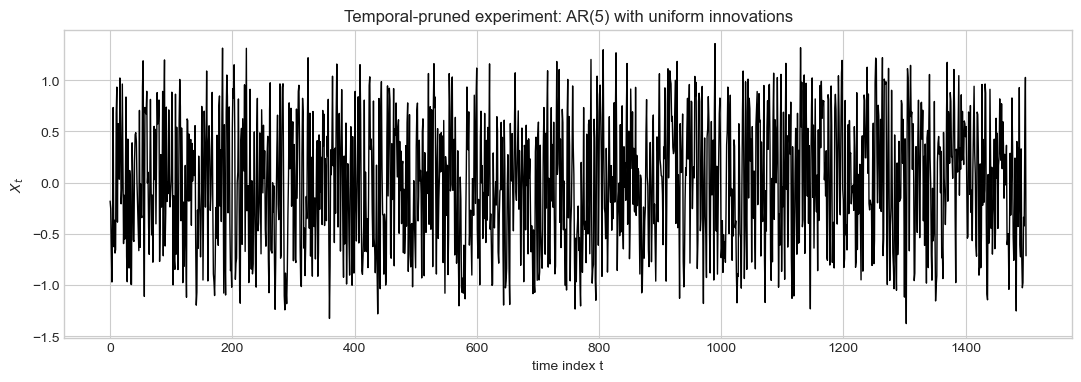

In [48]:
if TPG_PHI is None:
    tpg_phi = stable_default_ar_coefficients(TPG_P)
else:
    tpg_phi = np.asarray(TPG_PHI, dtype=float)
    if len(tpg_phi) != TPG_P:
        raise ValueError("TPG_PHI must have length TPG_P")

tpg_k_values = list(range(1, TPG_K_MAX + 1))
tpg_X = generate_ar_process(
    tpg_phi,
    TPG_N,
    innovation_kind="uniform",
    burn_in=TPG_BURN_IN,
    seed=TPG_SEED,
)

print(f"Generated AR({TPG_P}) process with uniform U[-1,1] innovations")
print(f"phi = {tpg_phi}")
print(f"tau = {TPG_TAU}")
print(f"temporal radius setting = {TPG_TEMPORAL_RADIUS}")
print(f"k values = {tpg_k_values}")
print(f"mean={tpg_X.mean():.4f}, std={tpg_X.std():.4f}, min={tpg_X.min():.4f}, max={tpg_X.max():.4f}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(np.arange(len(tpg_X)), tpg_X, lw=1.0, color="black")
ax.set_title(f"Temporal-pruned experiment: AR({TPG_P}) with uniform innovations")
ax.set_xlabel("time index t")
ax.set_ylabel(r"$X_t$")
plt.show()

In [49]:
tpg_prediction_results = {
    k: fit_predict_for_k(tpg_X, k, TPG_TRAIN_FRACTION)
    for k in tpg_k_values
}

tpg_graph_results = {
    k: build_temporal_pruned_prediction_graph(
        result,
        tau=TPG_TAU,
        temporal_radius=TPG_TEMPORAL_RADIUS,
    )
    for k, result in tpg_prediction_results.items()
}

for k, result in tpg_prediction_results.items():
    graph = tpg_graph_results[k]
    print(
        f"k={k:2d}: test MAE={result['error_test'].mean():.4f}, "
        f"base edges={graph['n_base_edges']:5d}, "
        f"kept edges={graph['n_edges']:5d}, "
        f"kept={graph['retained_fraction']:.3f}, "
        f"components={graph['n_components']:4d}, "
        f"largest={graph['largest_component_size']:4d} "
        f"({graph['largest_component_fraction']:.3f})"
    )

k= 1: test MAE=0.5289, base edges=  449, kept edges=   37, kept=0.082, components= 413, largest=   5 (0.011)
k= 2: test MAE=0.5244, base edges=  449, kept edges=   42, kept=0.094, components= 408, largest=   5 (0.011)
k= 3: test MAE=0.5203, base edges=  449, kept edges=   48, kept=0.107, components= 402, largest=   5 (0.011)
k= 4: test MAE=0.5220, base edges=  448, kept edges=   45, kept=0.100, components= 404, largest=   4 (0.009)
k= 5: test MAE=0.5189, base edges=  448, kept edges=   42, kept=0.094, components= 407, largest=   5 (0.011)
k= 6: test MAE=0.5189, base edges=  448, kept edges=   42, kept=0.094, components= 407, largest=   5 (0.011)
k= 7: test MAE=0.5166, base edges=  447, kept edges=   42, kept=0.094, components= 406, largest=   4 (0.009)
k= 8: test MAE=0.5167, base edges=  447, kept edges=   43, kept=0.096, components= 405, largest=   4 (0.009)
k= 9: test MAE=0.5167, base edges=  447, kept edges=   42, kept=0.094, components= 406, largest=   4 (0.009)
k=10: test MAE=0.51